In [3]:
# notebook cell — extract stable/unstable eigenvectors from the monodromy matrix
import numpy as np
import sys
sys.path.insert(0, '../src')
from cr3bp import cr3bp_rhs, integrate_with_stm, find_lagrange_points, MU_EARTH_MOON
from orbits import monodromy_and_multipliers, compute_family_pseudo_arclength, periodicity_constraint, family_tangent
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

mu = MU_EARTH_MOON
X_start = np.array([0.8359151258, 0.0084348855, 1.3458950464])
F0, dF0, _ = periodicity_constraint(X_start, mu)
t0 = family_tangent(dF0)
lps = find_lagrange_points(mu)
L1_family = compute_family_pseudo_arclength(
    X_start, ds=0.01, n_orbits=60, mu=mu, initial_direction=t0)


# Use a moderate-size L1 Lyapunov orbit (not the tiniest — bigger manifolds are clearer)
orbit = L1_family[20]   # adjust index as you like
state0 = np.array(orbit['state0'])
period = orbit['period']
print(f"Orbit: C = {orbit['jacobi']:.5f}, T = {period:.5f}")

# Monodromy matrix and its eigendecomposition
M, multipliers = monodromy_and_multipliers(state0, period, mu)
eigvals, eigvecs = np.linalg.eig(M)

print("\nFloquet multipliers and |lambda|:")
for i, lam in enumerate(eigvals):
    print(f"  lambda_{i} = {lam:.4f}   |lambda| = {abs(lam):.4f}")

# Identify the unstable (|lambda|>1, largest) and stable (|lambda|<1, smallest) directions
idx_unstable = np.argmax(np.abs(eigvals))   # largest magnitude
idx_stable = np.argmin(np.abs(eigvals))     # smallest magnitude

v_unstable = np.real(eigvecs[:, idx_unstable])  # eigenvector should be real for real lambda
v_stable = np.real(eigvecs[:, idx_stable])

print(f"\nUnstable eigenvector (lambda={eigvals[idx_unstable]:.2f}): {v_unstable}")
print(f"Stable eigenvector   (lambda={eigvals[idx_stable]:.4f}): {v_stable}")

# Normalize them to unit length
v_unstable = v_unstable / np.linalg.norm(v_unstable)
v_stable = v_stable / np.linalg.norm(v_stable)

  Orbit 0: x0=0.83592, vy0=0.00843, C=3.18828, T=2.69179
  Orbit 10: x0=0.82538, vy0=0.10591, C=3.17857, T=2.72702
  Orbit 20: x0=0.81723, vy0=0.19311, C=3.15514, T=2.82186
  Orbit 30: x0=0.81089, vy0=0.26300, C=3.12619, T=2.96357
  Orbit 40: x0=0.80544, vy0=0.31583, C=3.09870, T=3.13273
  Orbit 50: x0=0.80022, vy0=0.35601, C=3.07514, T=3.31546
Orbit: C = 3.15514, T = 2.82186

Floquet multipliers and |lambda|:
  lambda_0 = 1973.3722   |lambda| = 1973.3722
  lambda_1 = 0.0005   |lambda| = 0.0005
  lambda_2 = 1.0000   |lambda| = 1.0000
  lambda_3 = 1.0000   |lambda| = 1.0000

Unstable eigenvector (lambda=1973.37): [-0.33088662  0.09542663 -0.87303049  0.34529055]
Stable eigenvector   (lambda=0.0005): [ 0.33088662  0.09542663 -0.87303049 -0.34529055]


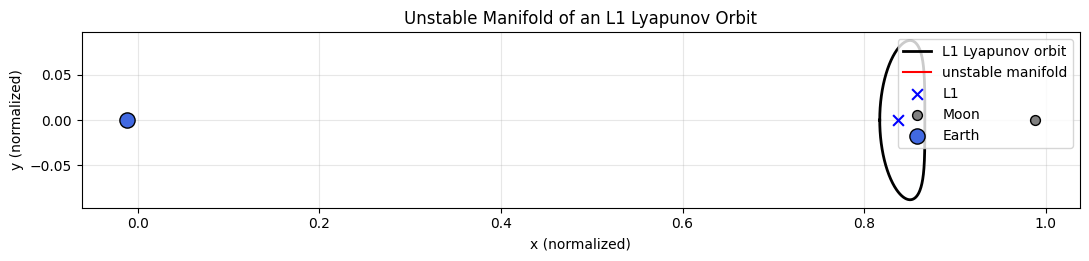

In [4]:
# notebook cell — compute and plot the unstable manifold of the L1 Lyapunov orbit
from orbits import compute_manifold

orbit = L1_family[20]
state0 = np.array(orbit['state0'])
period = orbit['period']

# Unstable manifold (integrate forward)
strands_unstable = compute_manifold(state0, period, mu, stable=False,
                                     n_points=40, epsilon=1e-6,
                                     integration_time=2.5)

# Plot: the orbit plus all the manifold strands
fig, ax = plt.subplots(figsize=(11, 9))

# The periodic orbit itself
sol_orbit = solve_ivp(cr3bp_rhs, (0, period), state0, args=(mu,),
                      method='DOP853', rtol=1e-11, atol=1e-11,
                      t_eval=np.linspace(0, period, 400))
ax.plot(sol_orbit.y[0], sol_orbit.y[1], 'k-', linewidth=2, label='L1 Lyapunov orbit', zorder=5)

# The manifold strands
for strand in strands_unstable:
    ax.plot(strand[:, 0], strand[:, 1], 'r-', linewidth=0.4, alpha=0.5)
ax.plot([], [], 'r-', label='unstable manifold')   # legend entry

ax.scatter([lps['L1'][0]], [0], color='blue', s=60, marker='x', zorder=6, label='L1')
ax.scatter([1-mu], [0], color='gray', s=50, edgecolor='black', zorder=6, label='Moon')
ax.scatter([-mu], [0], color='royalblue', s=120, edgecolor='black', zorder=6, label='Earth')
ax.set_aspect('equal')
ax.set_xlabel('x (normalized)'); ax.set_ylabel('y (normalized)')
ax.set_title('Unstable Manifold of an L1 Lyapunov Orbit')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# diagnostic — are the strands actually moving, and where do they go?
strands_unstable = compute_manifold(state0, period, mu, stable=False,
                                     n_points=40, epsilon=1e-6,
                                     integration_time=2.5)

print(f"Number of strands: {len(strands_unstable)}")
print(f"Each strand shape: {strands_unstable[0].shape}")

# Look at the first strand: how far does it travel from its start?
s = strands_unstable[0]
start_pt = s[0]
end_pt = s[-1]
print(f"\nFirst strand:")
print(f"  start: x={start_pt[0]:.6f}, y={start_pt[1]:.6f}")
print(f"  end:   x={end_pt[0]:.6f}, y={end_pt[1]:.6f}")
print(f"  distance traveled: {np.linalg.norm(end_pt[:2] - start_pt[:2]):.6e}")

# Overall extent of ALL strands
all_pts = np.vstack(strands_unstable)
print(f"\nAll strands combined:")
print(f"  x range: [{all_pts[:,0].min():.4f}, {all_pts[:,0].max():.4f}]")
print(f"  y range: [{all_pts[:,1].min():.4f}, {all_pts[:,1].max():.4f}]")
print(f"\nFor reference, orbit extent:")
print(f"  x range: [{sol_orbit.y[0].min():.4f}, {sol_orbit.y[0].max():.4f}]")
print(f"  y range: [{sol_orbit.y[1].min():.4f}, {sol_orbit.y[1].max():.4f}]")

Number of strands: 40
Each strand shape: (500, 4)

First strand:
  start: x=0.817225, y=0.000000
  end:   x=0.825822, y=-0.056841
  distance traveled: 5.748717e-02

All strands combined:
  x range: [0.8170, 0.8669]
  y range: [-0.0878, 0.0879]

For reference, orbit extent:
  x range: [0.8172, 0.8669]
  y range: [-0.0878, 0.0878]


All strands x range: [-0.7796, 0.8669]
All strands y range: [-0.6222, 0.4997]
Orbit x range: [0.8172, 0.8669]


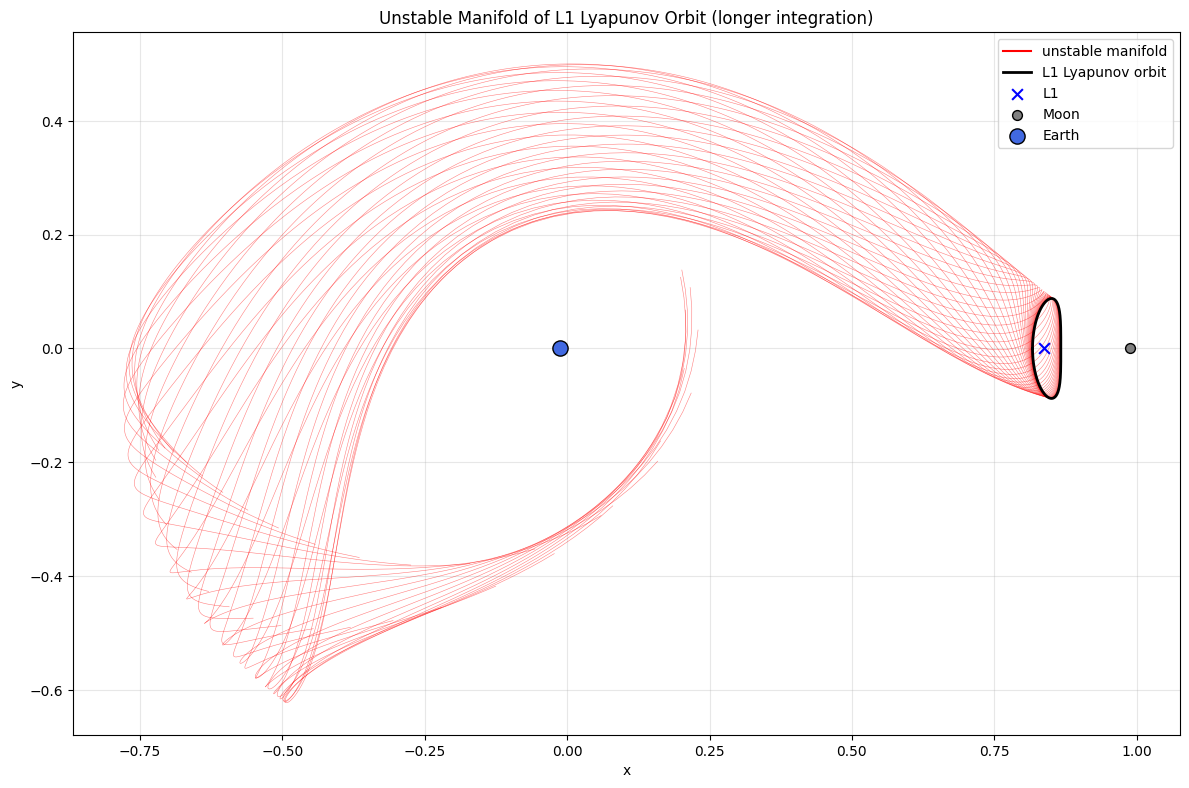

In [6]:
# Compute the unstable manifold with LONGER integration so strands escape
strands_unstable = compute_manifold(state0, period, mu, stable=False,
                                     n_points=40, epsilon=1e-6,
                                     integration_time=8.0)   # ~3 periods, up from 2.5

# Check how far they travel now
all_pts = np.vstack(strands_unstable)
print(f"All strands x range: [{all_pts[:,0].min():.4f}, {all_pts[:,0].max():.4f}]")
print(f"All strands y range: [{all_pts[:,1].min():.4f}, {all_pts[:,1].max():.4f}]")
print(f"Orbit x range: [{sol_orbit.y[0].min():.4f}, {sol_orbit.y[0].max():.4f}]")

# Plot
fig, ax = plt.subplots(figsize=(12, 10))
sol_orbit = solve_ivp(cr3bp_rhs, (0, period), state0, args=(mu,),
                      method='DOP853', rtol=1e-11, atol=1e-11,
                      t_eval=np.linspace(0, period, 400))
for strand in strands_unstable:
    ax.plot(strand[:, 0], strand[:, 1], 'r-', linewidth=0.4, alpha=0.5)
ax.plot([], [], 'r-', label='unstable manifold')
ax.plot(sol_orbit.y[0], sol_orbit.y[1], 'k-', linewidth=2, label='L1 Lyapunov orbit', zorder=5)
ax.scatter([lps['L1'][0]], [0], color='blue', s=60, marker='x', zorder=6, label='L1')
ax.scatter([1-mu], [0], color='gray', s=50, edgecolor='black', zorder=6, label='Moon')
ax.scatter([-mu], [0], color='royalblue', s=120, edgecolor='black', zorder=6, label='Earth')
ax.set_aspect('equal')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('Unstable Manifold of L1 Lyapunov Orbit (longer integration)')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

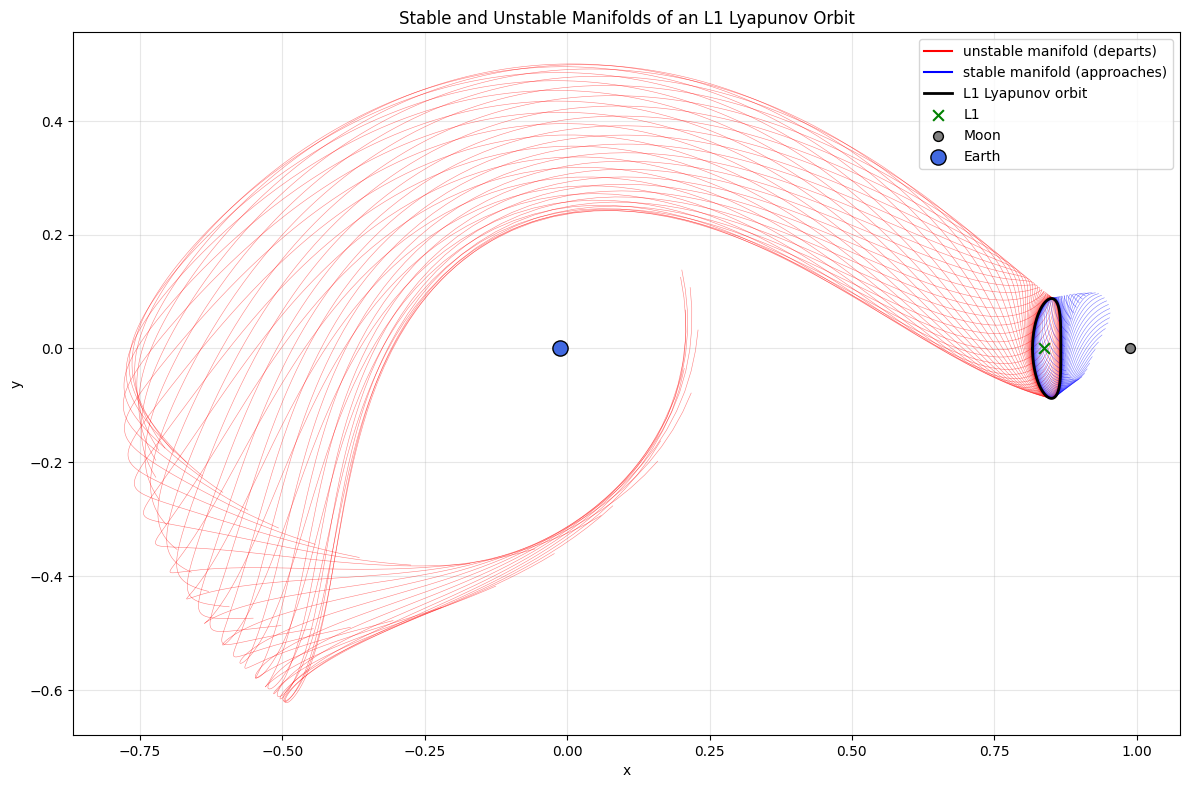

In [10]:
# Compute the STABLE manifold (integrate backward) and plot both together
strands_stable = compute_manifold(state0, period, mu, stable=True,
                                   n_points=40, epsilon=1e-6,
                                   integration_time=4.5)

fig, ax = plt.subplots(figsize=(12, 10))

# Both manifolds
for strand in strands_unstable:
    ax.plot(strand[:, 0], strand[:, 1], 'r-', linewidth=0.4, alpha=0.5)
for strand in strands_stable:
    ax.plot(strand[:, 0], strand[:, 1], 'b-', linewidth=0.4, alpha=0.5)
ax.plot([], [], 'r-', label='unstable manifold (departs)')
ax.plot([], [], 'b-', label='stable manifold (approaches)')

# Orbit and bodies
ax.plot(sol_orbit.y[0], sol_orbit.y[1], 'k-', linewidth=2, label='L1 Lyapunov orbit', zorder=5)
ax.scatter([lps['L1'][0]], [0], color='green', s=60, marker='x', zorder=6, label='L1')
ax.scatter([1-mu], [0], color='gray', s=50, edgecolor='black', zorder=6, label='Moon')
ax.scatter([-mu], [0], color='royalblue', s=120, edgecolor='black', zorder=6, label='Earth')
ax.set_aspect('equal')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('Stable and Unstable Manifolds of an L1 Lyapunov Orbit')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()